# Modeling: CNN-GRU regressor for quentin_house

**Goal of this notebook:** train a model that maps each scenario's indoor-temperature and
heating-power time series to the six target indicators (HLC, HLC_mit, HLC_ext, tau_b, tau_n,
tau_inf), then evaluate it against a realistic baseline.

This follows directly from `1_eda_clean.ipynb`:
- The normalization statistics (`Scalers`) and the 70/15/15 split are already fitted and saved
  there, on the training split only. This notebook only loads them.
- The physics checks found two hard constraints that hold in **physical units**: the sum rule
  HLC = HLC_mit + HLC_ext, and the ordering tau_n < tau_inf < tau_b (every target positive).
  Z-scoring breaks both, so they must be checked after denormalizing.
- The nearest-neighbour test found a **data ceiling**: scenarios whose temperature curves stay
  within 0.05 degC of each other for the full 8 hours still differ by about 24-29 W/K in HLC,
  almost as much as two random scenarios (30 W/K). Model errors below should be judged against
  this ceiling, not against zero.

**Architecture** (`src/coenergy/models.py`): a CNN-GRU backbone (4 conv blocks + a bidirectional
GRU, fed temperature, heating power and their derivative dT/dt) feeding one of two heads:
- **Plain head** -- 6 free outputs, read directly as normalized targets. Nothing is enforced.
- **Physics head** -- 5 free outputs passed through softplus so that, by construction,
  HLC = HLC_mit + HLC_ext exactly, every target is positive, and tau_n < tau_inf < tau_b.

**Plan**
1. Build both heads on the same backbone and train them with the same budget
   (`src/coenergy/training.py`: AdamW, one-cycle LR, early stopping on validation loss).
2. Compare their training curves and their test-set accuracy, per target.
3. Check how often the plain head breaks the constraints the physics head guarantees.
4. Break errors down by subset (hot, high-HLC, constant-heating) and compare them with the
   EDA's data ceiling.


## 1. Setup


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from coenergy.data import load_splits
from coenergy.preprocessing import Scalers

SEED = 67
torch.manual_seed(SEED)
np.random.seed(SEED)

# This notebook lives in notebooks/, so the project root is one level up
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / 'data' / 'quentin_house'
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR = PROJECT_ROOT / 'models'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_PATH = PROJECT_ROOT / 'data' / 'splits' / f'split_70_15_15_seed{SEED}.pt'
SCALER_PATH = PROJECT_ROOT / 'data' / 'splits' / f'scalers_seed{SEED}.pt'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

print(f'torch {torch.__version__} | device: {DEVICE}')


torch 2.11.0+cu128 | device: cuda


## 2. Load the normalized data

`Scalers` was fitted on the training split only, in the EDA. `load_splits` re-applies it to
every split and returns the normalized inputs and targets, reading the raw batches one at a
time so the raw dataset is never held in memory next to its normalized copy.


In [2]:
# Scalers fitted on the training split in the EDA notebook
scalers = Scalers.load(SCALER_PATH)
assert scalers.seed == SEED, 'Scalers were fitted on a different split'
print(f'Loaded scalers from {SCALER_PATH}')
print(f'temperature mean {scalers.temp_mean:.3f} | std {scalers.temp_std:.3f} | excitation scale {scalers.exc_scale:.0f} W')
print('targets:', scalers.target_labels)

Loaded scalers from c:\Users\Youssef\Desktop\coenergy-assessment\data\splits\scalers_seed67.pt
temperature mean 30.560 | std 4.788 | excitation scale 7000 W
targets: ['HLC', 'HLC_mit', 'HLC_ext', 'tau_b', 'tau_n', 'tau_inf']


In [3]:
# Batches are read one at a time and written into preallocated split tensors,
# so the raw dataset is never held in memory next to its normalized copy.
data = load_splits(DATA_DIR, SPLIT_PATH, scalers)
train, val, test = data['train'], data['val'], data['test']

total_gb = sum(d.x.nbytes + d.y.nbytes for d in data.values()) / 1e9
for name, d in data.items():
    print(f'{name:5s} x {tuple(d.x.shape)} | y {tuple(d.y.shape)}')
print(f'Memory used by the normalized tensors: {total_gb:.2f} GB')

train x (700000, 2, 480) | y (700000, 6)
val   x (150000, 2, 480) | y (150000, 6)
test  x (150000, 2, 480) | y (150000, 6)
Memory used by the normalized tensors: 3.86 GB


In [4]:
# Sanity checks on the normalized data
for name, d in data.items():
    temp, exc = d.x[:, 0], d.x[:, 1]
    print(f'--- {name} ---')
    print(f'temperature  {temp.min():6.2f} to {temp.max():5.2f} | mean {temp.mean():+.3f} std {temp.std():.3f}')
    print(f'excitation   values {torch.unique(exc).tolist()}')
    for j, lbl in enumerate(scalers.target_labels):
        print(f'{lbl:8s}  {d.y[:, j].min():6.2f} to {d.y[:, j].max():5.2f} | mean {d.y[:, j].mean():+.3f} std {d.y[:, j].std():.3f}')

# The sum rule must still hold after converting back to physical units
phys = scalers.denorm_targets(val.y)
gap = (phys[:, 0] - phys[:, 1] - phys[:, 2]).abs().max().item()
print(f'\nval: max |HLC - (HLC_mit + HLC_ext)| = {gap:.2e} W/K')
del phys

--- train ---
temperature   -1.32 to  4.38 | mean +0.000 std 1.000
excitation   values [0.0, 1.0]
HLC        -3.88 to  4.31 | mean +0.000 std 1.000
HLC_mit    -2.96 to  4.16 | mean +0.000 std 1.000
HLC_ext    -3.25 to  4.29 | mean -0.000 std 1.000
tau_b      -2.95 to  7.14 | mean +0.000 std 1.000
tau_n      -2.92 to  7.37 | mean +0.000 std 1.000
tau_inf    -2.76 to  7.50 | mean -0.000 std 1.000
--- val ---
temperature   -1.32 to  3.96 | mean +0.003 std 1.001
excitation   values [0.0, 1.0]
HLC        -3.49 to  4.06 | mean +0.004 std 1.001
HLC_mit    -2.84 to  4.23 | mean +0.003 std 1.000
HLC_ext    -3.36 to  3.95 | mean +0.002 std 1.001
tau_b      -2.83 to  6.73 | mean -0.003 std 1.001
tau_n      -2.70 to  6.40 | mean -0.001 std 0.998
tau_inf    -2.50 to  7.26 | mean -0.002 std 1.000
--- test ---
temperature   -1.31 to  3.82 | mean +0.000 std 1.001
excitation   values [0.0, 1.0]
HLC        -3.31 to  3.96 | mean -0.000 std 1.001
HLC_mit    -2.71 to  4.21 | mean +0.002 std 1.001
HLC_ext  

**Observations**

The per-split statistics match the training split closely: on validation and test, every
column's mean stays within +/-0.004 and its standard deviation between 0.998 and 1.005 of the
training fit (0.0 / 1.0 exactly on train, by construction). The sum rule still holds after
denormalizing (max residual 3.05e-05 W/K on validation, float32 rounding) -- normalization does
not need to touch it, since it is enforced in physical units.


## 3. Model architecture

`derivative_std` gives the scale of the dT/dt channel the backbone adds internally, fitted on
the training inputs. `physics_head_scales` (called inside `build_cnn_gru` for the physics head)
sets the head's scales so that a raw output of 0 predicts the training mean of each physical
quantity (softplus(0) = ln 2) -- a sensible, cheap initialization.

Both models share the same backbone hyperparameters (`width=64`, 2 GRU layers) and only differ
in the head, so any gap between them is attributable to the constraint, not to capacity.


In [5]:
from coenergy.models import build_cnn_gru, derivative_std

dT_std = derivative_std(train.x)
y_train_phys = scalers.denorm_targets(train.y)

model_plain = build_cnn_gru('plain', dT_std, scalers.tgt_mean, scalers.tgt_std)
model_physics = build_cnn_gru(
    'physics', dT_std, scalers.tgt_mean, scalers.tgt_std, y_train_phys=y_train_phys,
)

for name, model in [('plain', model_plain), ('physics', model_physics)]:
    n_params = sum(p.numel() for p in model.parameters())
    print(f'{name:8s} head | {n_params:,} parameters')


plain    head | 246,214 parameters
physics  head | 246,085 parameters


## 4. Training configuration

`TrainConfig` sets the optimizer (AdamW with weight decay), a one-cycle learning-rate schedule,
and early stopping on the validation loss, which is the normalized MSE averaged over all six
targets (z-scored, so HLC and the time constants weigh the same despite their very different
scales). The defaults below are the ones already set in `src/coenergy/training.py`; both heads
are trained with the exact same config for a fair comparison.


In [6]:
from coenergy.training import TrainConfig, train_model

cfg = TrainConfig(seed=SEED)
cfg


TrainConfig(epochs=20, batch_size=256, lr=0.002, weight_decay=0.0001, patience=4, eval_batch_size=4096, max_train=None, data_on_device=True, seed=67)

## 5. Train the plain-head model

The best weights (by validation loss) are checkpointed to `models/cnn_gru_plain.pt` and loaded
back into `model_plain` at the end of training.


In [7]:
history_plain = train_model(
    model_plain, train, val, scalers, cfg, device=DEVICE,
    checkpoint_path=CKPT_DIR / 'cnn_gru_plain.pt',
)
history_plain.tail()


epoch  1 | train 0.8691 | val 0.8471 | R2 HLC 0.325 HLC_mit 0.233 HLC_ext 0.145 tau_b 0.024 tau_n 0.164 tau_inf 0.025 | 37s
epoch  2 | train 0.8221 | val 0.8341 | R2 HLC 0.322 HLC_mit 0.233 HLC_ext 0.223 tau_b 0.027 tau_n 0.163 tau_inf 0.028 | 37s
epoch  3 | train 0.7897 | val 0.7881 | R2 HLC 0.346 HLC_mit 0.223 HLC_ext 0.338 tau_b 0.086 tau_n 0.208 tau_inf 0.070 | 36s
epoch  4 | train 0.7714 | val 0.7977 | R2 HLC 0.366 HLC_mit 0.249 HLC_ext 0.352 tau_b 0.010 tau_n 0.212 tau_inf 0.024 | 36s
epoch  5 | train 0.7629 | val 0.7845 | R2 HLC 0.352 HLC_mit 0.238 HLC_ext 0.369 tau_b 0.052 tau_n 0.224 tau_inf 0.058 | 37s
epoch  6 | train 0.7567 | val 0.7509 | R2 HLC 0.405 HLC_mit 0.261 HLC_ext 0.404 tau_b 0.109 tau_n 0.231 tau_inf 0.085 | 37s
epoch  7 | train 0.7510 | val 0.7534 | R2 HLC 0.394 HLC_mit 0.262 HLC_ext 0.393 tau_b 0.110 tau_n 0.234 tau_inf 0.087 | 37s
epoch  8 | train 0.7465 | val 0.7431 | R2 HLC 0.409 HLC_mit 0.263 HLC_ext 0.422 tau_b 0.120 tau_n 0.235 tau_inf 0.093 | 36s
epoch  9

,train_loss,val_loss,R2_HLC,R2_HLC_mit,R2_HLC_ext,R2_tau_b,R2_tau_n,R2_tau_inf,lr,time_s
epoch,,,,,,,,,,
16,0.711933,0.722476,0.432790,0.277271,0.460715,0.132799,0.258967,0.102305,3.764525e-04,36.476130
17,0.707091,0.721380,0.434104,0.277812,0.463180,0.133494,0.260636,0.102198,2.181245e-04,36.520176
18,0.702881,0.720751,0.434923,0.278220,0.465663,0.133412,0.260861,0.102108,9.900313e-05,36.509325
19,0.699715,0.720524,0.435174,0.278093,0.466231,0.133715,0.261105,0.102234,2.506173e-05,36.473401
20,0.698078,0.720558,0.435448,0.278286,0.466406,0.133521,0.260740,0.101944,8.003368e-09,36.445490


## 6. Train the physics-head model

Same data, same `cfg`, only the head differs.


In [8]:
history_physics = train_model(
    model_physics, train, val, scalers, cfg, device=DEVICE,
    checkpoint_path=CKPT_DIR / 'cnn_gru_physics.pt',
)
history_physics.tail()


epoch  1 | train 0.8674 | val 0.8502 | R2 HLC 0.316 HLC_mit 0.230 HLC_ext 0.137 tau_b 0.029 tau_n 0.159 tau_inf 0.028 | 37s
epoch  2 | train 0.8280 | val 0.8148 | R2 HLC 0.346 HLC_mit 0.240 HLC_ext 0.220 tau_b 0.059 tau_n 0.196 tau_inf 0.050 | 37s
epoch  3 | train 0.7891 | val 0.8119 | R2 HLC 0.368 HLC_mit 0.237 HLC_ext 0.324 tau_b 0.007 tau_n 0.178 tau_inf 0.015 | 37s
epoch  4 | train 0.7684 | val 0.7974 | R2 HLC 0.376 HLC_mit 0.253 HLC_ext 0.363 tau_b -0.002 tau_n 0.210 tau_inf 0.016 | 37s
epoch  5 | train 0.7628 | val 0.7786 | R2 HLC 0.336 HLC_mit 0.234 HLC_ext 0.356 tau_b 0.104 tau_n 0.215 tau_inf 0.084 | 37s
epoch  6 | train 0.7571 | val 0.7554 | R2 HLC 0.387 HLC_mit 0.246 HLC_ext 0.405 tau_b 0.110 tau_n 0.233 tau_inf 0.087 | 37s
epoch  7 | train 0.7519 | val 0.7463 | R2 HLC 0.405 HLC_mit 0.263 HLC_ext 0.414 tau_b 0.117 tau_n 0.232 tau_inf 0.091 | 37s
epoch  8 | train 0.7475 | val 0.7471 | R2 HLC 0.400 HLC_mit 0.257 HLC_ext 0.418 tau_b 0.118 tau_n 0.231 tau_inf 0.093 | 37s
epoch  

,train_loss,val_loss,R2_HLC,R2_HLC_mit,R2_HLC_ext,R2_tau_b,R2_tau_n,R2_tau_inf,lr,time_s
epoch,,,,,,,,,,
16,0.715997,0.721540,0.433281,0.277906,0.461111,0.134374,0.260035,0.103759,3.764525e-04,36.637164
17,0.711764,0.720050,0.434873,0.278054,0.464627,0.135963,0.261460,0.104421,2.181245e-04,36.585977
18,0.708290,0.718569,0.436980,0.280333,0.467082,0.136415,0.262741,0.104727,9.900313e-05,36.838319
19,0.705375,0.718184,0.437085,0.279963,0.468329,0.136869,0.263319,0.105022,2.506173e-05,36.851359
20,0.704015,0.717998,0.437693,0.280375,0.468710,0.136873,0.263131,0.104923,8.003368e-09,36.641225


## 7. Training curves

Loss curves (normalized MSE) and per-target validation R2 across epochs, for both heads.


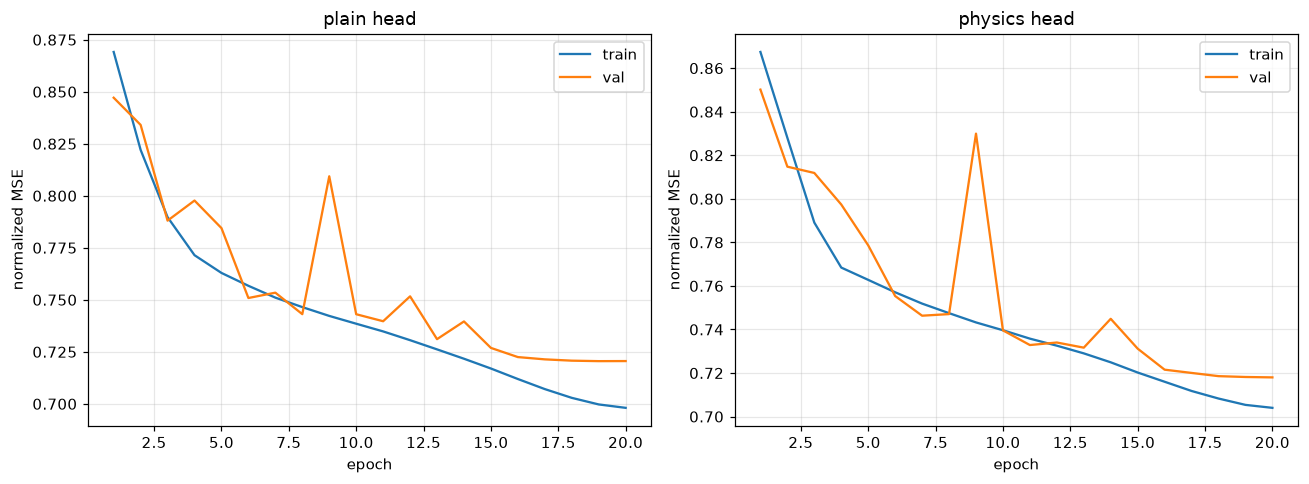

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, hist) in zip(axes, [('plain', history_plain), ('physics', history_physics)]):
    ax.plot(hist.index, hist['train_loss'], label='train')
    ax.plot(hist.index, hist['val_loss'], label='val')
    ax.set_title(f'{name} head')
    ax.set_xlabel('epoch')
    ax.set_ylabel('normalized MSE')
    ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'training_curves.png', dpi=150)
plt.show()


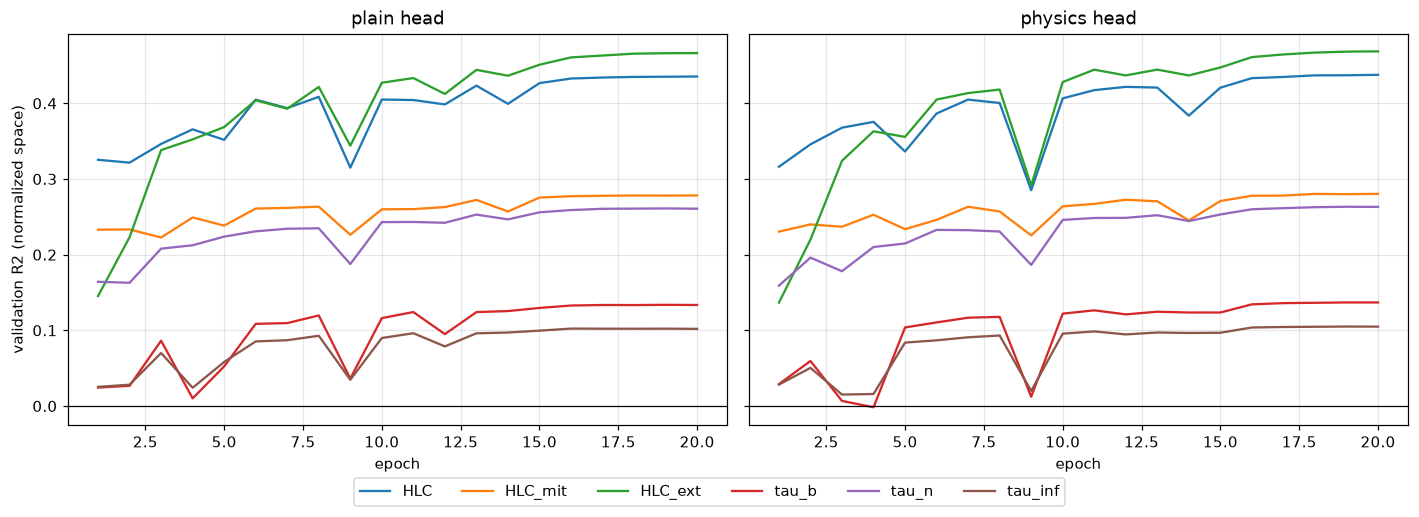

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (name, hist) in zip(axes, [('plain', history_plain), ('physics', history_physics)]):
    for lbl in scalers.target_labels:
        ax.plot(hist.index, hist[f'R2_{lbl}'], label=lbl)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(f'{name} head')
    ax.set_xlabel('epoch')
axes[0].set_ylabel('validation R2 (normalized space)')
fig.legend(scalers.target_labels, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.05))
fig.tight_layout()
fig.savefig(FIG_DIR / 'training_r2.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Evaluation on the test set

`per_target_metrics` (`src/coenergy/metrics.py`) reports MAE, RMSE, P95 absolute error, relative
MAE and R2 for each target, all in physical units (W/K for the HLC family, hours for the time
constants). Both heads are evaluated on the same held-out test split.


In [11]:
from coenergy.metrics import per_target_metrics, constraint_violations
from coenergy.training import predict

y_test_phys = scalers.denorm_targets(test.y)

pred_plain = predict(model_plain, test.x, cfg.eval_batch_size)
pred_physics = predict(model_physics, test.x, cfg.eval_batch_size)

metrics_plain = per_target_metrics(pred_plain, y_test_phys, scalers.target_labels)
metrics_physics = per_target_metrics(pred_physics, y_test_phys, scalers.target_labels)

comparison = pd.concat({'plain': metrics_plain, 'physics': metrics_physics}, axis=1)
comparison.round(3)


plain                                            physics             \
            MAE       RMSE    P95_abs  rel_MAE_%     R2        MAE       RMSE   
HLC      18.799  23.580000  46.229000   8.246000  0.434  18.787001  23.542999   
HLC_mit  17.948  22.346001  43.629002  15.826000  0.277  17.923000  22.313999   
HLC_ext   9.969  12.458000  24.225000   9.126000  0.468   9.953000  12.439000   
tau_b     7.404   9.420000  18.141001  15.164000  0.135   7.397000   9.409000   
tau_n     1.358   1.732000   3.354000  12.394000  0.264   1.359000   1.730000   
tau_inf   5.592   7.152000  13.712000  18.561001  0.105   5.589000   7.145000   

                                     
           P95_abs rel_MAE_%     R2  
HLC      46.152000     8.225  0.436  
HLC_mit  43.543999    15.759  0.280  
HLC_ext  24.223000     9.105  0.470  
tau_b    18.118000    15.155  0.137  
tau_n     3.346000    12.426  0.265  
tau_inf  13.705000    18.559  0.106

**Data ceiling, for reference** -- from the EDA's nearest-neighbour test (`1_eda_clean.ipynb`,
section 8): the median absolute gap between near-identical curves (within 0.05 degC for 8
hours), against the same gap for random pairs. It is not the same statistic as the MAE above
(median absolute gap between pairs, vs. mean absolute error against the true value), so treat
this as an order-of-magnitude sanity check, not an exact bound: a model's MAE well above the
"random pairs" column is clearly under-using the inputs, and getting close to the
"near-identical curves" column is close to the best this data can support.


In [12]:
ceiling = pd.DataFrame({
    'near-identical curves': [26.5, 23.5, 14.0, 9.15, 1.68, 6.7],
    'random pairs': [30.0, 25.5, 16.6, 9.2, 1.82, 6.8],
}, index=scalers.target_labels)
ceiling


,near-identical curves,random pairs
HLC,26.50,30.00
HLC_mit,23.50,25.50
HLC_ext,14.00,16.60
tau_b,9.15,9.20
tau_n,1.68,1.82
tau_inf,6.70,6.80


## 9. Physics constraints

`constraint_violations` reports, for each head's test predictions, the share of scenarios that
break the sum rule (|HLC - HLC_mit - HLC_ext| > 1e-3 W/K), have a non-positive target, or get the
tau ordering wrong. The physics head should score (near) 0 on all three by construction; any gap
left for the plain head is a constraint it had to learn on its own, with no guarantee.


In [13]:
violations = pd.DataFrame({
    'plain': constraint_violations(pred_plain),
    'physics': constraint_violations(pred_physics),
})
violations


,plain,physics
sum_rule,0.94782,0.0
non_positive,0.00000,0.0
tau_order,0.00000,0.0


## 10. Error by subset

The EDA flagged three kinds of unusual scenarios on the training split (section 10): **hot**
(indoor temperature above 45 degC), **high HLC** (above 300 W/K), and **constant heating**
(never switches on/off). The same definitions are applied here directly to the test split's own
tensors -- denormalizing temperature and HLC, and checking the heating-power channel's
std -- so no raw data needs to be reloaded.


In [14]:
temp_max_test = (test.x[:, 0] * scalers.temp_std + scalers.temp_mean).max(dim=1).values
flag_hot = temp_max_test > 45.0
flag_high_hlc = y_test_phys[:, 0] > 300.0
flag_const = test.x[:, 1].std(dim=1) == 0

print(f'test scenarios: {len(test):,}')
for name, mask in [('hot', flag_hot), ('high HLC', flag_high_hlc), ('constant heating', flag_const)]:
    print(f'{name:18s} {mask.sum().item():>7,} ({mask.float().mean():.2%})')


test scenarios: 150,000
hot                    119 (0.08%)
high HLC             2,808 (1.87%)
constant heating    13,978 (9.32%)


In [15]:
subsets = {
    'overall': torch.ones(len(test), dtype=torch.bool),
    'hot': flag_hot,
    'high HLC': flag_high_hlc,
    'constant heating': flag_const,
}
rows = []
for subset_name, mask in subsets.items():
    for head, pred in [('plain', pred_plain), ('physics', pred_physics)]:
        mae = per_target_metrics(pred[mask], y_test_phys[mask], scalers.target_labels)['MAE']
        rows.append({'subset': subset_name, 'head': head, 'n': int(mask.sum()), **mae.to_dict()})
subset_mae = pd.DataFrame(rows).set_index(['subset', 'head'])
subset_mae.round(2)


n    HLC  HLC_mit  HLC_ext  tau_b  tau_n  \
subset           head                                                     
overall          plain    150000  18.80    17.95     9.97   7.40   1.36   
                 physics  150000  18.79    17.92     9.95   7.40   1.36   
hot              plain       119  10.94    10.52     8.40   7.68   0.98   
                 physics     119  11.17    10.19     8.14   7.86   0.96   
high HLC         plain      2808  45.64    37.26    12.23  11.37   2.57   
                 physics    2808  46.14    37.67    12.28  11.41   2.59   
constant heating plain     13978  20.85    18.87     9.74   7.13   1.36   
                 physics   13978  20.87    18.91     9.73   7.12   1.37   

                          tau_inf  
subset           head              
overall          plain       5.59  
                 physics     5.59  
hot              plain       5.10  
                 physics     5.11  
high HLC         plain       8.76  
                 physics     8.79  
constant heating plain       5.44  
                 physics     5.43

## 11. Summary

_Fill in after running the cells above -- the bullets below are the questions to answer, not
the answers._

- **Plain vs. physics head:** which has the lower test MAE per target, and is the gap large
  enough to matter? Does the physics head's guaranteed sum rule / positivity / ordering come at
  a cost in raw accuracy, or is it free?
- **Constraint violations (section 9):** how often does the plain head actually break the sum
  rule or the tau ordering, in practice?
- **Against the data ceiling (section 8):** for which targets is the test MAE close to the
  "near-identical curves" ceiling (good use of the model, little room left), and for which is
  it still closer to "random pairs" (the model is not yet extracting what little signal is
  there)? The EDA expected tau_b and tau_inf to be the hardest, since an 8-hour window cannot
  show a 50-hour decay.
- **Subsets (section 10):** is either head noticeably worse on the hot, high-HLC, or
  constant-heating scenarios? The hot subset is small (~0.08% of the data, so a few hundred
  test rows), so treat its metrics as noisy.
- **Checkpoints:** the best weights for each head are saved under `models/`, alongside the
  scalers and split indices in `data/splits/`, which is everything needed to reproduce
  inference on new scenarios.

**Next steps**, if time allows: evaluate on a split by heating schedule (scenarios with a
heating pattern never seen in training) rather than by scenario, to see whether the model
relies on memorizing specific schedules.
